# PSD projection and convex domains

Symmetry is an explicit matrix-cone requirement. The antisymmetric input component contributes a constant loss. Perspective and square-root domains accompany transformed convex inequalities.

See [theory](../docs/theory.md), [protocol](../docs/protocol.md) and [limitations](../docs/model_cards.md).

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
ROOT=Path.cwd()
if ROOT.name=='notebooks': ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'src'))
def read(path): return json.loads((ROOT/path).read_text())
def figure(name): display(Image(filename=str(ROOT/'assets/figures'/f'{name}.png')))


## Nonsymmetric input

In [2]:
from optimization_lab.convex_cases import nearest_psd
a=np.array([[1.,3.],[-1.,-2.]])
r=nearest_psd(a)
p=r["arrays"]["projection"]
assert np.allclose(p,p.T) and np.linalg.eigvalsh(p).min()>-1e-10
print(p)

[[1.19337525 0.36132495]
 [0.36132495 0.10940039]]


## Domain witnesses

In [3]:
m=read("results/reference/geometry/metrics.json")
assert max(r["maximum_violation"] for r in m["rows"])<1e-7
pd.DataFrame(m["rows"])

,domain,reference,witness,maximum_violation
0,simplex,"{'solver': 'CLARABEL', 'status': 'optimal', 'o...","[0.29999999998124854, 0.399999999948868]",0.0
1,nonnegative_order,"{'solver': 'CLARABEL', 'status': 'optimal', 'o...","[1.0000000000373959, 0.4999999999953881]",0.0
2,perspective_quadratic,"{'solver': 'CLARABEL', 'status': 'optimal', 'o...","[0.9999999999988284, 0.9999999999934508]",0.0
3,concave_sqrt_hypograph,"{'solver': 'CLARABEL', 'status': 'optimal', 'o...","[0.9999999999986605, -5.997745135156002e-12, 0...",0.0


## Original PSD example

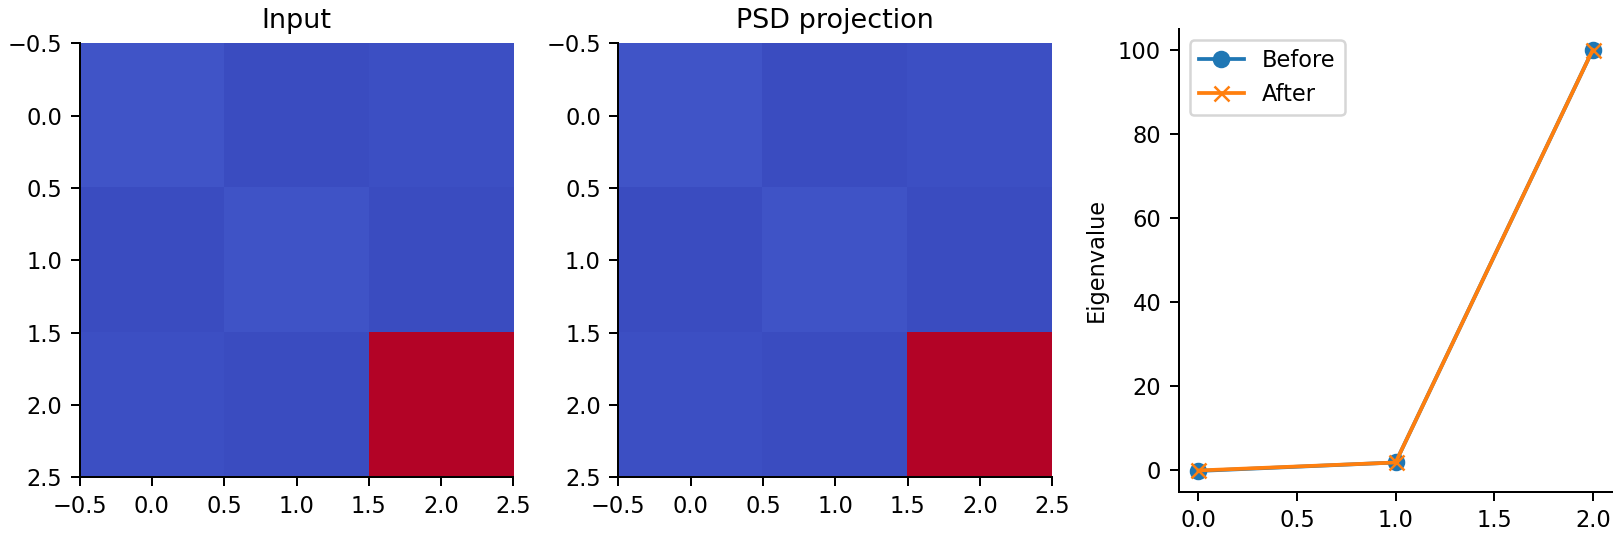

In [4]:
figure("psd_projection")

Full training / search commands and cache provenance are in [reproduction](../docs/reproduction.md). This notebook inspects actually completed evidence and small analytical checks; opening it does not launch the full fitting campaign.